# Quiet Sun, 3 December 2015 — Sharma & Oberoi 2020 Figure 4, step by step

A walk-through you can run in front of other people. Kernel: `solar-burst-multiview`.

**The question.** For a very quiet four minutes (03:39–03:44 UT), can we follow the 2020 pipeline and get the same radio pictures and the same brightness in million K?

**The short answer, so nobody is misled while we go through the steps:**

| | 108 MHz | 162 MHz | 217 MHz |
|---|---|---|---|
| Paper caption, peak | 0.92 million K | 1.20 | 1.50 |
| His maps, paper flux method | **0.89** | 1.00 | 1.06 |
| Kelvin same as the paper? | **yes** | not yet | not yet |

Shape (disk + western patch) matches. We remade one half-second from the visibilities with the settings in his files. The 108 MHz blob is now close in size to his; 162 and 217 MHz came out too sharp. Kelvin on *his* maps is the caption comparison. The remake is a shape-and-size check.

**How to use this.** Run in order. Markdown above a cell is what to say. Comments in the code are for you.



## 1. Tools

Nothing is plotted yet.



In [1]:
from pathlib import Path
import json
import sys
import warnings

import numpy as np
import matplotlib.pyplot as plt
from astropy.coordinates import AltAz, EarthLocation, SkyCoord, get_body
from astropy.time import Time
from astropy.io import fits
from astropy.wcs import FITSFixedWarning
import astropy.units as u
from IPython.display import Image, display
from matplotlib.patches import Circle, Ellipse

warnings.filterwarnings("ignore", category=FITSFixedWarning)
%matplotlib inline
plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.size"] = 11



## 2. Find the project folder



In [2]:
here = Path.cwd()
if (here / "src" / "solarburst").exists():
    ROOT = here
elif (here.parent / "src" / "solarburst").exists():
    ROOT = here.parent
else:
    raise SystemExit("Cannot find src/solarburst. Open the notebook from the repo.")

src = ROOT / "src"
if str(src) not in sys.path:
    sys.path.insert(0, str(src))

from solarburst.haslam import HASLAM_ALPHA, HASLAM_CITE, HaslamMap, haslam_path
from solarburst.maps import (
    frequency_hz,
    header_cell_arcsec,
    hpc_extent,
    jybeam_to_tb,
    load_casa_2d,
    solar_pixel,
    crop_around_sun,
)
from solarburst.mohan2017 import scale_image
from solarburst.sharma2020 import last_clean_from_history, list_fits, CLEAN

print("project folder:", ROOT)



project folder: /Users/csillag/Projects/solar-burst-multiview


## 3. Check that the files are on disk

If a line says **MISSING**, stop. The new remake lives under `paper_casa_su` (SuperUniform, 8000 steps). The older remake `paper_casa` used the wrong mix (Briggs, 2500 steps) and is kept only as a contrast.



In [3]:
PATHS = {
    "Rohit maps, Figure 4 layout": ROOT / "figures" / "sharma2020" / "fig4.png",
    "same maps, paper kelvin": ROOT / "figures" / "sharma2020" / "fig4_paper.png",
    "Haslam sky at this pointing": ROOT / "figures" / "sharma2020" / "haslam_sky.png",
    "per-frame kelvin (4 min mean)": ROOT / "data" / "quiet2015" / "fig4_tb_perframe.npz",
    "whole-Sun flux tables": ROOT / "data" / "quiet2015" / "paper_flux",
    "Haslam 1982 FITS": haslam_path(),
    "Rohit CASA FITS": ROOT / "data" / "sharma2022" / "20151203_MWA" / "new_ms" / "fits",
    "our remake, SuperUniform": ROOT / "data" / "quiet2015" / "paper_casa_su",
    "older remake, Briggs": ROOT / "data" / "quiet2015" / "paper_casa",
}
for name, path in PATHS.items():
    ok = path.exists()
    extra = f"  ({len(list(path.glob('*')))} files)" if path.is_dir() and ok else ""
    print(f"{'ok      ' if ok else 'MISSING '}  {name:36s}  {path}{extra}")



ok        Rohit maps, Figure 4 layout           /Users/csillag/Projects/solar-burst-multiview/figures/sharma2020/fig4.png
ok        same maps, paper kelvin               /Users/csillag/Projects/solar-burst-multiview/figures/sharma2020/fig4_paper.png
ok        Haslam sky at this pointing           /Users/csillag/Projects/solar-burst-multiview/figures/sharma2020/haslam_sky.png
ok        per-frame kelvin (4 min mean)         /Users/csillag/Projects/solar-burst-multiview/data/quiet2015/fig4_tb_perframe.npz
ok        whole-Sun flux tables                 /Users/csillag/Projects/solar-burst-multiview/data/quiet2015/paper_flux  (17 files)
ok        Haslam 1982 FITS                      /Users/csillag/Projects/solar-burst-multiview/data/haslam/lambda_haslam408_nofilt.fits
ok        Rohit CASA FITS                       /Users/csillag/Projects/solar-burst-multiview/data/sharma2022/20151203_MWA/new_ms/fits  (35948 files)
ok        our remake, SuperUniform              /Users/csillag/Projects/sol

## 4. Words we will keep using

| Word | Meaning |
|---|---|
| **Rohit** | Rohit Sharma, first author. His processed pictures. |
| **Visibilities** | What the telescope recorded: each antenna pairing, every 0.5 s. Not a picture yet. |
| **CASA** | The picture-making program the 2020 paper used. |
| **SuperUniform** | How to mix short and long antenna pairings. His files used this. Short pairings see the whole disk; long pairings see small detail. SuperUniform tries to count them more evenly. Result: a tighter blob. |
| **Briggs** | A different mix of the same pairings. We used this first, by mistake. Result: a fatter blob (291″ vs his 225″ at 108 MHz). |
| **8000 steps** | How many times the cleaner peels a point off the picture. His files: 8000. Our first remake: 2500. |
| **Half-second frame** | One 0.5 s picture. Four minutes → ~570 of them. Figure 4 is the average. |
| **Whole-Sun brightness** | One number per frequency, in solar flux units, from the short antenna pairings *without* making a map. Oberoi 2017. |
| **Haslam map** | The 408 MHz picture of the whole radio sky (Haslam et al. 1982). It is the Milky Way, not the Sun. |
| **FEKO** | A commercial program that simulates a metal antenna. Oberoi used it for how an MWA tile listens to the sky. Those files were never published. We used a simple 4×4 grid of dipoles instead. |
| **Million K** | Brightness temperature. Quiet corona is roughly 0.5–1.5 million K here. |

Four frequencies: **108, 162, 217, 240 MHz**. Figure 4 top row uses the first three.



In [4]:
BANDS = ("108", "162", "217", "240")
CHAN = {"108": "084-085", "162": "125-126", "217": "169-170", "240": "187-188"}
PAPER_PEAKS = {"108": 0.92, "162": 1.20, "217": 1.50, "240": None}  # million K
RSUN = 958.0
FOV = 2500.0
NPIX = 100



## 5. One drawing helper

Brown rings = 1× and 2× the optical Sun, centred on the Sun.



In [5]:
def draw_map(ax, tb, extent, beam, title, *, stretch_to_peak=False, vmax_mk=1.7):
    tb_mk = np.asarray(tb, dtype=float) / 1e6
    peak = float(np.nanmax(tb_mk))
    shown = np.where(tb_mk > 0.2, tb_mk, np.nan)
    vmax = peak if stretch_to_peak else vmax_mk
    im = ax.imshow(
        shown, origin="lower", extent=extent, cmap="jet",
        vmin=0.0, vmax=vmax, interpolation="nearest",
    )
    ax.add_patch(Circle((0, 0), RSUN, fill=False, color="saddlebrown", lw=1.2))
    ax.add_patch(Circle((0, 0), 2 * RSUN, fill=False, color="saddlebrown", lw=1.0, ls="--"))
    if beam is not None:
        bmaj, bmin, bpa = beam
        ax.add_patch(Ellipse(
            (-0.72 * FOV, -0.72 * FOV),
            width=bmin * 3600, height=bmaj * 3600, angle=-bpa,
            fill=False, color="black", lw=1.1,
        ))
    ax.set_xlim(-FOV, FOV)
    ax.set_ylim(-FOV, FOV)
    ax.set_aspect("equal")
    ax.set_title(title, fontsize=10)
    ax.text(0.03, 0.97, f"peak {peak:.2f} MK", transform=ax.transAxes, va="top", fontsize=8)
    ax.set_xlabel("Solar X (arcsec)")
    ax.set_ylabel("Solar Y (arcsec)")
    return im



---

# Step 1 — What the paper published

These are Rohit’s CASA maps, averaged over four minutes, drawn in the paper’s 3×3 layout. **Not** a photocopy of the journal PDF. **Not** our remake.



## 6. Figure 4 layout



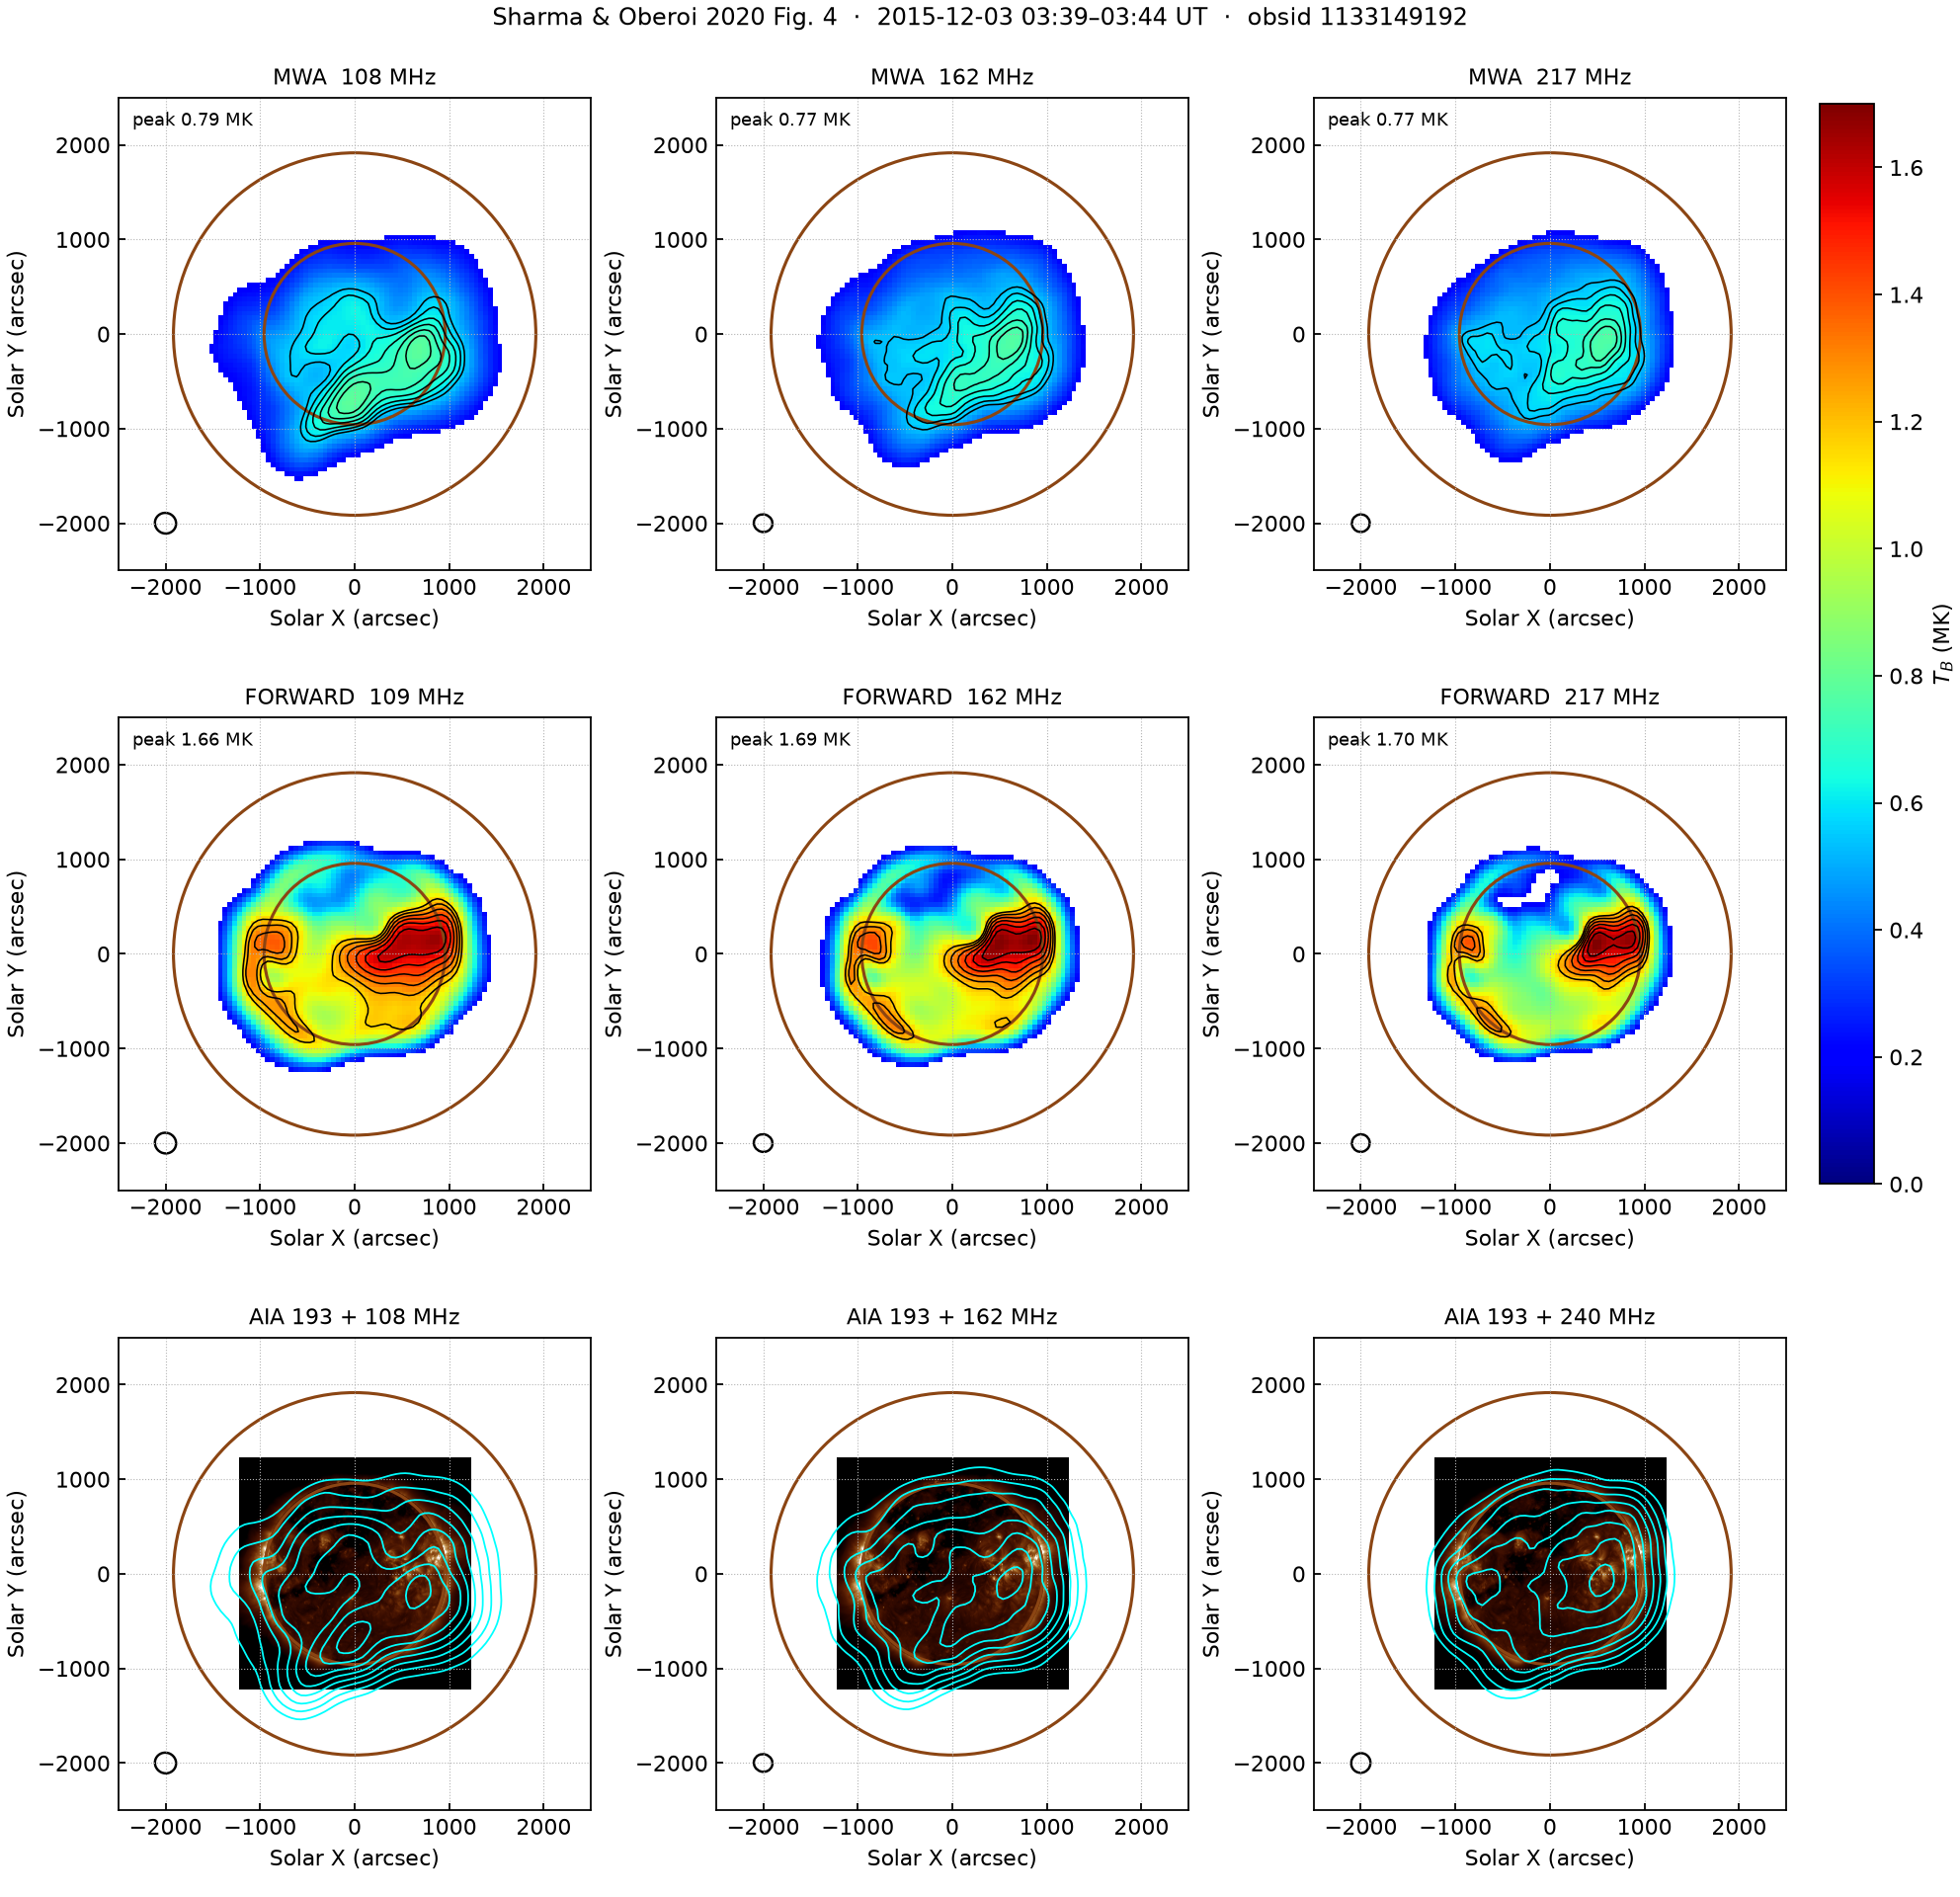

/Users/csillag/Projects/solar-burst-multiview/figures/sharma2020/fig4.png


In [6]:
png = PATHS["Rohit maps, Figure 4 layout"]
display(Image(filename=str(png), width=900))
print(png)



## 7. Load the 4-minute mean already converted the 2020 way

Each of the 570 half-second frames was stretched so the disk equals the whole-Sun flux, converted to kelvin, then averaged. That is §4 of the paper. Cache from `python scripts/sharma2020_pipeline.py`.



In [7]:
packed = np.load(PATHS["per-frame kelvin (4 min mean)"])
rohit = {}
for lab in BANDS:
    rohit[lab] = {
        "tb": packed[f"{lab}_tb"],
        "extent": packed[f"{lab}_extent"],
        "beam": (float(packed[f"{lab}_bmaj_deg"]), float(packed[f"{lab}_bmin_deg"]),
                 float(packed[f"{lab}_bpa_deg"])),
        "f_nu_mean": float(packed[f"{lab}_f_nu_mean"]),
        "f_nu_std": float(packed[f"{lab}_f_nu_std"]),
        "n": int(packed[f"{lab}_n"]),
    }
    peak = rohit[lab]["tb"].max() / 1e6
    cap = PAPER_PEAKS[lab]
    cap_s = f"{cap:.2f}" if cap else "—"
    print(f"{lab} MHz  {rohit[lab]['n']} frames  F(ν)={rohit[lab]['f_nu_mean']:.2f}±{rohit[lab]['f_nu_std']:.2f}  "
          f"peak {peak:.3f} MK  caption {cap_s}")



108 MHz  570 frames  F(ν)=10.73±0.07  peak 0.892 MK  caption 0.92
162 MHz  570 frames  F(ν)=12.26±0.10  peak 0.996 MK  caption 1.20
217 MHz  570 frames  F(ν)=13.19±0.18  peak 1.064 MK  caption 1.50
240 MHz  570 frames  F(ν)=13.10±0.22  peak 0.621 MK  caption —


## 8. 108 MHz, paper colour scale

Ask: disk plus western patch? Inner brown ring = optical Sun. Peak should sit next to 0.92 million K.



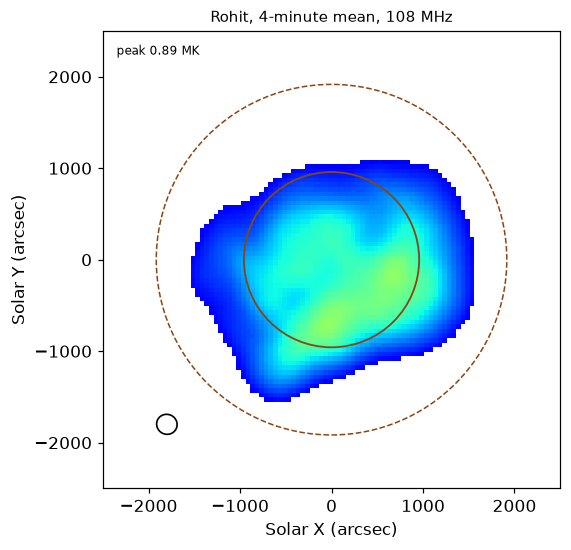

In [8]:
fig, ax = plt.subplots(figsize=(5.4, 5.4))
m = rohit["108"]
draw_map(ax, m["tb"], m["extent"], m["beam"], "Rohit, 4-minute mean, 108 MHz")
plt.show()



## 9. All four frequencies



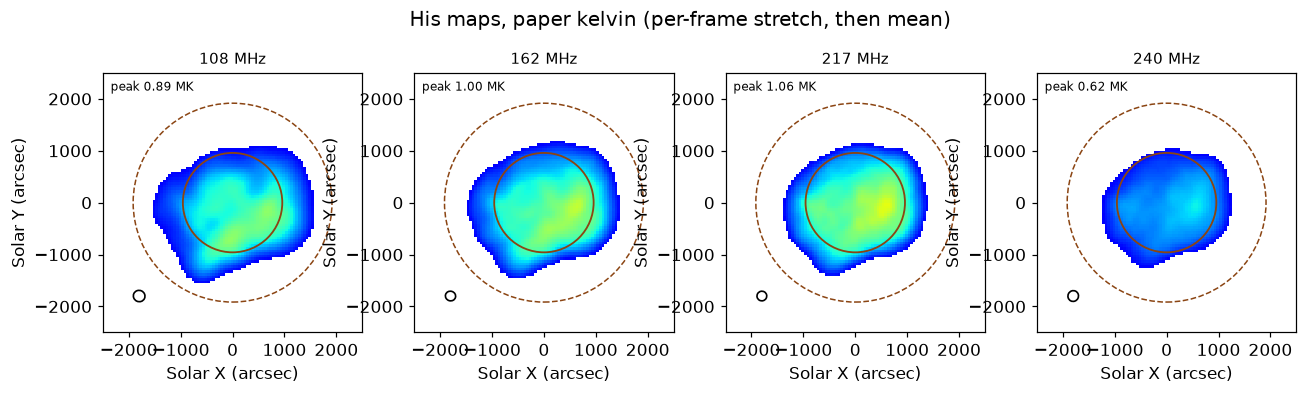

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
for ax, lab in zip(axes, BANDS):
    m = rohit[lab]
    draw_map(ax, m["tb"], m["extent"], m["beam"], f"{lab} MHz")
fig.suptitle("His maps, paper kelvin (per-frame stretch, then mean)")
plt.show()



---

# Step 2 — Read the recipe from his files

Do not guess the imaging settings. They are written in the FITS HISTORY.



## 10. Last clean() that wrote the published pictures

CASA 5.3, SuperUniform, Hogbom, 8000 steps, gain 0.1. Same at every frequency. The paper text mentions a per-band UV-range; these files have none.



In [10]:
print("What we now use for a remake:")
for k, v in CLEAN.items():
    print(f"  {k:14s} {v}")
print()
fitsdir = PATHS["Rohit CASA FITS"]
for lab in BANDS:
    paths = list_fits(fitsdir, CHAN[lab])
    rec = last_clean_from_history(paths[0])
    print(f"{lab} MHz  {len(paths)} frames  {paths[0].name}")
    for k, v in rec.items():
        print(f"    {k:14s} {v}")



What we now use for a remake:
  task           clean
  imsize         [1024, 1024]
  cell           50arcsec
  stokes         I
  mode           mfs
  weighting      superuniform
  npixels        0
  psfmode        hogbom
  imagermode     
  niter          8000
  gain           0.1
  threshold      0mJy
  uvrange        
  phasecenter    J2000 16h40m55.28s -19d40m25.38s



108 MHz  570 frames  1133149192-084-085.0010.image_image.FITS
    origin         CASA 5.3.0-143
    bmaj_arcsec    225.4
    bmin_arcsec    217.7
    fitted_beam    Fitted beam used in restoration: 225.416 by 217.6
    niter          Clean gain = 0.1, Niter = 8000, Threshold = 0 mJy
    deconvolver    Using multifield Hogbom clean
    weighting      SuperUniform weighting over a square cell spannin


162 MHz  570 frames  1133149192-125-126.0010.image_image.FITS
    origin         CASA 5.3.0-143
    bmaj_arcsec    198.3
    bmin_arcsec    185.6
    fitted_beam    Fitted beam used in restoration: 198.271 by 185.6
    niter          Clean gain = 0.1, Niter = 8000, Threshold = 0 mJy
    deconvolver    Using multifield Hogbom clean
    weighting      SuperUniform weighting over a square cell spannin
217 MHz  570 frames  1133149192-169-170.0010.image_image.FITS
    origin         CASA 5.3.0-143
    bmaj_arcsec    188.1
    bmin_arcsec    185.7
    fitted_beam    Fitted beam used in restoration: 188.088 by 185.7
    niter          Clean gain = 0.1, Niter = 8000, Threshold = 0 mJy
    deconvolver    Using multifield Hogbom clean
    weighting      SuperUniform weighting over a square cell spannin


240 MHz  570 frames  1133149192-187-188.0010.image_image.FITS
    origin         CASA 5.3.0-143
    bmaj_arcsec    209.0
    bmin_arcsec    202.3
    fitted_beam    Fitted beam used in restoration: 209.001 by 202.3
    niter          Clean gain = 0.1, Niter = 8000, Threshold = 0 mJy
    deconvolver    Using multifield Hogbom clean
    weighting      SuperUniform weighting over a square cell spannin


---

# Step 3 — Whole-Sun brightness (no map)

The CASA pictures are in Jy/beam on an arbitrary scale (the gains). Kelvin needs one stretch so the disk equals the true brightness of the whole Sun. That number comes from the visibilities, not from the map: Oberoi, Sharma & Rogers (2017).



## 11. Why the Galaxy matters

The 3 December Sun sat on the Milky Way. Oberoi’s published sky table was a different day, high above the plane. We use Haslam 1982 — the survey he cites — at *this* pointing.



In [11]:
haslam = HaslamMap(PATHS["Haslam 1982 FITS"])
print(HASLAM_CITE)
print(f"  pixels  nside={haslam.nside}, T at 408 MHz "
      f"{haslam.temperature_k.min():.0f}–{haslam.temperature_k.max():.0f} K")

t = Time("2015-12-03T03:42:04")
loc = EarthLocation.of_site("MWA")
sun = get_body("sun", t, location=loc)
altaz = sun.transform_to(AltAz(obstime=t, location=loc))
# Line of sight toward the Sun, in Galactic coordinates (not the 3-D Sun vector).
los = SkyCoord(az=altaz.az, alt=altaz.alt, frame=AltAz(obstime=t, location=loc))
gal = los.transform_to("galactic")
print(f"Sun: az {altaz.az.deg:.1f}°, altitude {altaz.alt.deg:.1f}°")
print(f"that direction: Galactic l={gal.l.deg:.1f}°, b={gal.b.deg:.1f}°  (b near 0° = looking at the Milky Way)")

def t_at(coord, mhz):
    t408 = float(np.asarray(haslam.at_408(coord)).squeeze())
    return t408, t408 * (mhz / 408.0) ** HASLAM_ALPHA

print(f"\n{'where':<28s}  {'T 408 MHz':>10s}  {'T 108 MHz':>10s}")
for name, c in (
    ("Galactic centre", SkyCoord(0 * u.deg, 0 * u.deg, frame="galactic")),
    ("North Galactic pole", SkyCoord(0 * u.deg, 90 * u.deg, frame="galactic")),
    ("this Sun, 3 Dec 2015", los),
):
    t408, t108 = t_at(c, 108.0)
    print(f"{name:<28s}  {t408:10.0f} K  {t108:10.0f} K")



Haslam et al. 1982, A&AS 47, 1
  pixels  nside=512, T at 408 MHz 11–4817 K


Sun: az 46.5°, altitude 83.4°
that direction: Galactic l=356.3°, b=16.9°  (b near 0° = looking at the Milky Way)

where                          T 408 MHz   T 108 MHz
Galactic centre                     1926 K       57106 K
North Galactic pole                   21 K         610 K
this Sun, 3 Dec 2015                  58 K        1715 K


## 12. The sky above the horizon that morning



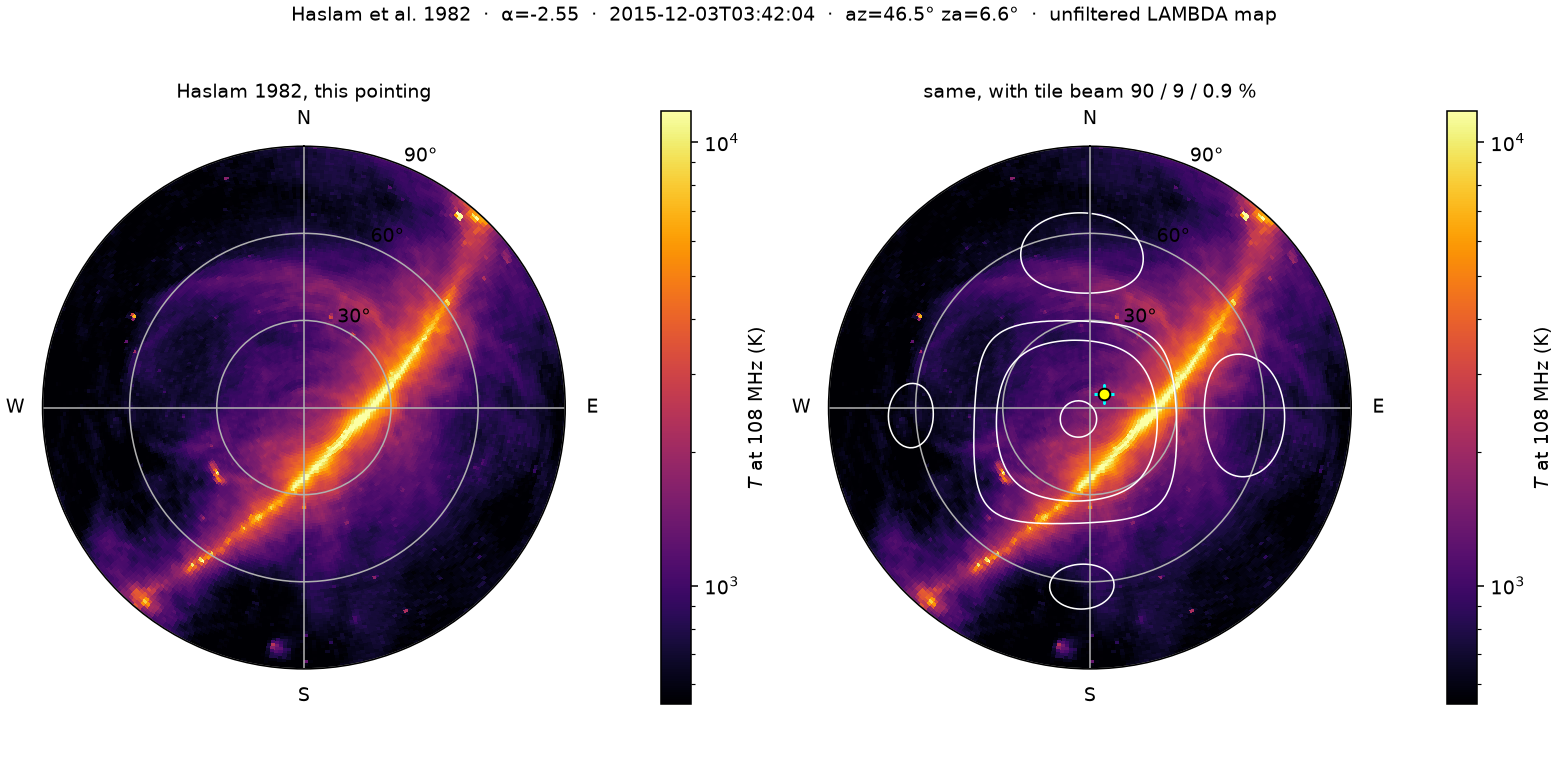

In [12]:
png = PATHS["Haslam sky at this pointing"]
display(Image(filename=str(png), width=720))



## 13. Whole-Sun flux from the recordings

Short pairings of Tile011, 021, 022, 023. Combined with the Haslam sky at this pointing.



In [13]:
flux_dir = PATHS["whole-Sun flux tables"]
s_odot = {}
print(f"{'MHz':>5s}  {'r_N':>8s}  {'S_⊙ SFU':>10s}  {'T_Sky K':>8s}")
for lab in BANDS:
    rec = json.loads((flux_dir / f"{lab}MHz_full.json").read_text())
    s_odot[lab] = float(rec["s_odot_sfu"])
    print(f"{lab:>5s}  {rec['r_N']:8.3f}  {s_odot[lab]:10.3f}  {rec.get('t_sky_K', float('nan')):8.0f}")



  MHz       r_N     S_⊙ SFU   T_Sky K
  108     0.094       2.868      2191
  162     0.333       6.500       699
  217     0.521      11.719       300
  240     0.470       8.166       218


---

# Step 4 — Stretch each frame, then average

`F(ν) = (whole-Sun flux) / (disk in that map)`. Almost constant over the four minutes (~1% scatter). That is why a mean-then-stretch and a stretch-then-mean look the same. The paper’s wording is stretch-then-mean. We did that.



## 14. F(ν) versus a frozen 9.48

9.48 is a 2022 shortcut (stored cubes / textbook conversion, one frame). The 2020 paper computes F(ν) per band from this observation. Same *kind* of number, not the same number.



In [14]:
print(f"{'MHz':>5s}  {'F(ν)':>8s}  {'9.48':>8s}  {'peak MK':>8s}  {'caption':>8s}")
for lab in BANDS:
    peak = rohit[lab]["tb"].max() / 1e6
    cap = PAPER_PEAKS[lab]
    cap_s = f"{cap:8.2f}" if cap else f"{'—':>8s}"
    print(f"{lab:>5s}  {rohit[lab]['f_nu_mean']:8.2f}  {9.48:8.2f}  {peak:8.3f}  {cap_s}")



  MHz      F(ν)      9.48   peak MK   caption
  108     10.73      9.48     0.892      0.92
  162     12.26      9.48     0.996      1.20
  217     13.19      9.48     1.064      1.50
  240     13.10      9.48     0.621         —


## 15. The three-row figure on this kelvin scale



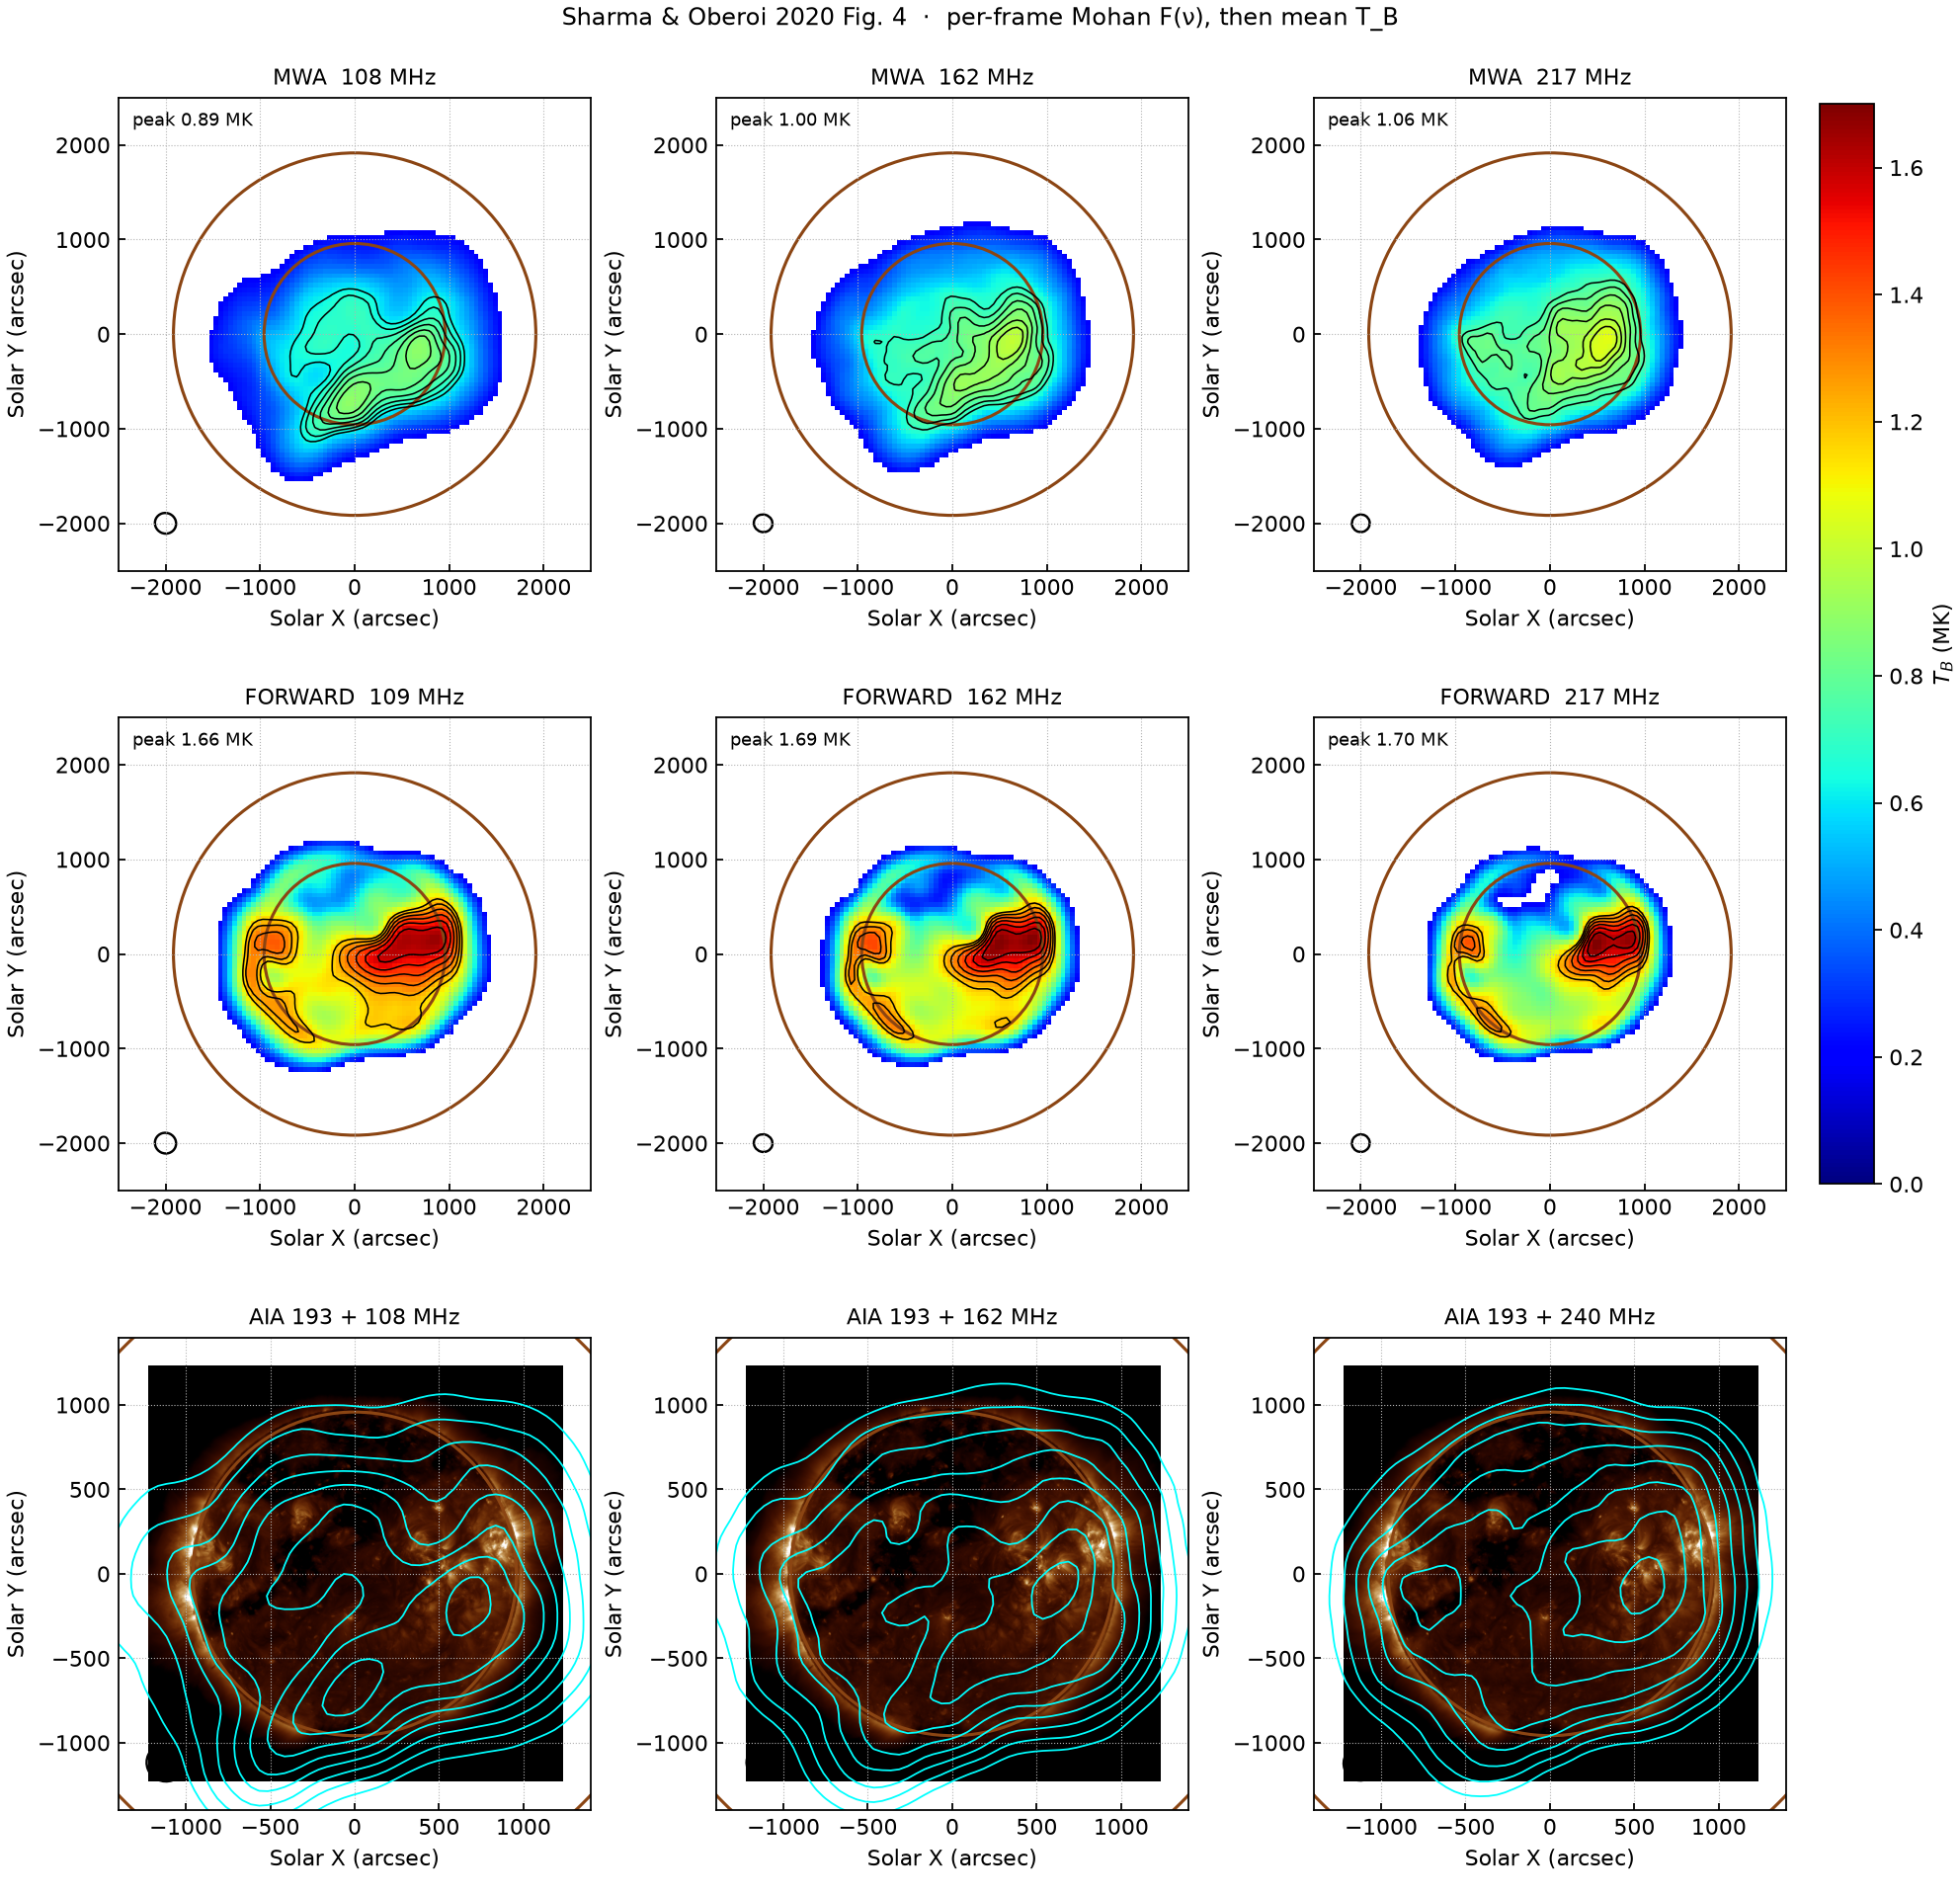

/Users/csillag/Projects/solar-burst-multiview/figures/sharma2020/fig4_paper.png


In [15]:
png = PATHS["same maps, paper kelvin"]
display(Image(filename=str(png), width=900))
print(png)



---

# Step 5 — Remake one half-second from the visibilities

Same calibrated recordings. Settings from his HISTORY: SuperUniform, 8000 steps. One frame in the middle of the scan (03:42:04), not 570 averaged. Compare **shape** and **blob size**, not kelvin — these remakes are not yet stretched to the whole-Sun number.

CASA on the cluster is 6.6 `tclean`. His files are 5.3 `clean`. If the blob size still misses, that version gap is what to ask Rohit.



## 16. Load three versions of the same moment, cropped on the Sun



In [16]:
def load_frame(path: Path) -> dict:
    data, hdr = load_casa_2d(path)
    crop, origin, sun_xy = crop_around_sun(data, hdr, NPIX)
    extent = hpc_extent(
        NPIX, NPIX, cell_arcsec=header_cell_arcsec(hdr), sun_xy=sun_xy, origin=origin
    )
    nu = frequency_hz(hdr)
    tb = jybeam_to_tb(crop, nu, hdr["BMAJ"], hdr["BMIN"], scale=1.0)
    return {
        "tb": tb,
        "extent": extent,
        "beam": (float(hdr["BMAJ"]), float(hdr["BMIN"]), float(hdr.get("BPA", 0.0))),
        "bmaj_arcsec": float(hdr["BMAJ"]) * 3600,
        "bmin_arcsec": float(hdr["BMIN"]) * 3600,
        "origin": str(hdr.get("ORIGIN", "")),
        "jy_peak": float(np.nanmax(crop)),
    }

mid = {}
print(f"{'MHz':>5s}  {'Rohit ″':>12s}  {'Briggs ″':>12s}  {'SuperU ″':>12s}  {'corr SU':>8s}")
for lab in BANDS:
    his = PATHS["Rohit CASA FITS"] / f"1133149192-{CHAN[lab]}.0306.image_image.FITS"
    briggs = PATHS["older remake, Briggs"] / f"{lab}MHz_mid.fits"
    su = PATHS["our remake, SuperUniform"] / f"{lab}MHz_mid.fits"
    mid[lab] = {
        "Rohit": load_frame(his),
        "Briggs": load_frame(briggs),
        "SuperUniform": load_frame(su),
    }
    a = np.nan_to_num(mid[lab]["Rohit"]["tb"]).ravel()
    b = np.nan_to_num(mid[lab]["SuperUniform"]["tb"]).ravel()
    corr = float(np.corrcoef(a, b)[0, 1])
    def beam(tag):
        r = mid[lab][tag]
        return f"{r['bmaj_arcsec']:.0f}x{r['bmin_arcsec']:.0f}"
    print(f"{lab:>5s}  {beam('Rohit'):>12s}  {beam('Briggs'):>12s}  {beam('SuperUniform'):>12s}  {corr:8.3f}")
print("blob size = restoring beam in arcsec (smaller = sharper). corr = shape vs his frame.")



  MHz       Rohit ″      Briggs ″      SuperU ″   corr SU


  108       225x217       291x278       217x205     0.999


  162       198x185       226x207       160x150     1.000


  217       189x186       158x146       128x119     0.999


  240       208x202       223x210       183x157     0.999
blob size = restoring beam in arcsec (smaller = sharper). corr = shape vs his frame.


## 17. 108 MHz, three versions of the same half-second

Left = his. Middle = our first remake (wrong mix: Briggs). Right = new remake (SuperUniform, 8000 steps). Colour is stretched to each panel’s own peak so you see shape, not kelvin.



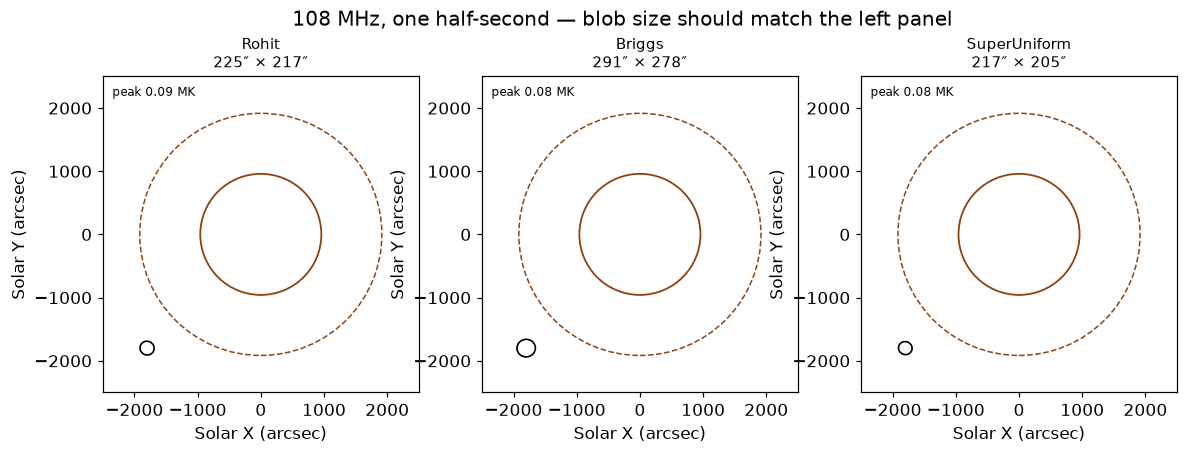

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(12.6, 4.2))
for ax, tag in zip(axes, ("Rohit", "Briggs", "SuperUniform")):
    r = mid["108"][tag]
    title = f"{tag}\n{r['bmaj_arcsec']:.0f}″ × {r['bmin_arcsec']:.0f}″"
    draw_map(ax, r["tb"], r["extent"], r["beam"], title, stretch_to_peak=True)
fig.suptitle("108 MHz, one half-second — blob size should match the left panel")
plt.show()



## 18. Same three versions at 162 MHz

At 162 MHz the new remake is *too* sharp. Shape is still his Sun. Kelvin on these panels is not the caption.



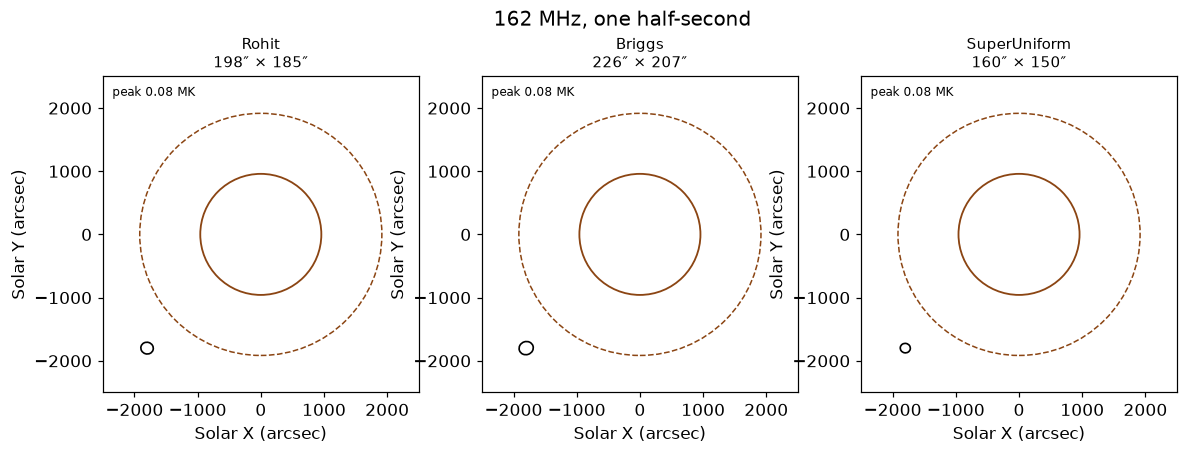

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(12.6, 4.2))
for ax, tag in zip(axes, ("Rohit", "Briggs", "SuperUniform")):
    r = mid["162"][tag]
    title = f"{tag}\n{r['bmaj_arcsec']:.0f}″ × {r['bmin_arcsec']:.0f}″"
    draw_map(ax, r["tb"], r["extent"], r["beam"], title, stretch_to_peak=True)
fig.suptitle("162 MHz, one half-second")
plt.show()



---

# Step 6 — What to say at the end



## 19. Scorecard



In [19]:
print(f"{'MHz':>5s}  {'caption':>8s}  {'his maps MK':>12s}  {'Rohit ″':>10s}  {'our SU ″':>10s}  {'corr':>6s}")
for lab in BANDS:
    cap = PAPER_PEAKS[lab]
    cap_s = f"{cap:8.2f}" if cap else f"{'—':>8s}"
    peak = rohit[lab]["tb"].max() / 1e6
    rh = mid[lab]["Rohit"]
    su = mid[lab]["SuperUniform"]
    a = np.nan_to_num(rh["tb"]).ravel()
    b = np.nan_to_num(su["tb"]).ravel()
    corr = float(np.corrcoef(a, b)[0, 1])
    print(f"{lab:>5s}  {cap_s}  {peak:12.3f}  {rh['bmaj_arcsec']:5.0f}x{rh['bmin_arcsec']:<4.0f}  "
          f"{su['bmaj_arcsec']:5.0f}x{su['bmin_arcsec']:<4.0f}  {corr:6.3f}")



  MHz   caption   his maps MK     Rohit ″    our SU ″    corr
  108      0.92         0.892    225x217     217x205    0.999
  162      1.20         0.996    198x185     160x150    1.000
  217      1.50         1.064    189x186     128x119    0.999
  240         —         0.621    208x202     183x157    0.999


## 20. Takeaway

**Same as the paper**

- Quiet-Sun shape: disk plus a western compact source, larger radio Sun at 108 MHz.
- At **108 MHz**, his maps with the 2020 flux method peak at 0.89 million K against the caption 0.92.
- Remaking from the visibilities did not invent a different Sun (correlation 0.999).
- At 108 MHz the new remake’s blob (217″) is close to his (225″). The old Briggs remake was 291″.

**Not the same**

- 162 MHz: 1.00 vs 1.20 million K. 217 MHz: 1.06 vs 1.50. Still low. That is the flux / tile-beam leftover, not the imager.
- New remake at 162 and 217 MHz is too sharp (160″ vs 198″, 128″ vs 189″). CASA 6.6 `tclean` vs his 5.3 `clean` is the first thing to ask.

**Ask Rohit**

- FEKO tile patterns (how the antenna really listens). We used a 4×4 dipole grid.
- Why 162/217 kelvin is higher in the paper than F(ν) from these visibilities.
- Per-band UV-range: the text says yes, these FITS say no.
- Confirm SuperUniform / 8000 at every frequency (HISTORY says yes).



In [20]:
print("pipeline scripts:")
print("  python scripts/sharma2020_fits_history.py")
print("  python scripts/sharma2020_pipeline.py --reuse")
print("  CASA remake (cluster): scripts/calculon/sharma2020_casa_snap.py")



pipeline scripts:
  python scripts/sharma2020_fits_history.py
  python scripts/sharma2020_pipeline.py --reuse
  CASA remake (cluster): scripts/calculon/sharma2020_casa_snap.py
